In [2]:
!pip install -q qiskit qiskit-aer networkx matplotlib scipy

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 9.8/9.8 MB 35.6 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 12.4/12.4 MB 69.2 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 2.4/2.4 MB 60.6 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 54.9/54.9 kB 4.5 MB/s eta 0:00:00


In [3]:
import itertools, numpy as np, networkx as nx
import matplotlib.pyplot as plt

# ESP32 nodes; weight = interference strength
edges = [(0,1,3),(0,2,2),(1,2,4),(1,3,1),
         (2,4,2),(3,4,3),(3,5,2),(4,5,4)]
n = 6
G = nx.Graph()
G.add_weighted_edges_from(edges)
W = sum(w for _,_,w in edges)

def cut_value(bits):  # bits[i] = channel of node i
    return sum(w for i,j,w in edges if bits[i] != bits[j])

best_classical, best_bits = max(
    ((cut_value(b), b) for b in itertools.product([0,1], repeat=n)))
print("Brute-force optimal cut:", best_classical, best_bits)

Brute-force optimal cut: 17 (1, 0, 1, 1, 0, 1)


In [4]:
from qiskit import QuantumCircuit
from qiskit.circuit import ParameterVector
from qiskit.quantum_info import SparsePauliOp, Statevector
from scipy.optimize import minimize

p = 2
params = ParameterVector("t", 2*p)

H = SparsePauliOp.from_sparse_list(
    [("ZZ", [i,j], w/2) for i,j,w in edges], num_qubits=n)

qc = QuantumCircuit(n)
qc.h(range(n))
for k in range(p):
    gamma, beta = params[2*k], params[2*k+1]
    for i,j,w in edges:
        qc.rzz(gamma*w, i, j)
    qc.rx(2*beta, range(n))

def energy(x):
    sv = Statevector(qc.assign_parameters(x))
    return sv.expectation_value(H).real

history, best = [], None
rng = np.random.default_rng(1)
for _ in range(8):  # random restarts
    x0 = rng.uniform(0, np.pi, 2*p)
    res = minimize(energy, x0, method="COBYLA",
                   callback=lambda xk: history.append(energy(xk)))
    if best is None or res.fun < best.fun:
        best = res

exp_cut = W/2 - best.fun
print("QAOA expected cut:", round(exp_cut,3))
print("Approximation ratio:", round(exp_cut/best_classical,3))

QAOA expected cut: 14.104
Approximation ratio: 0.83


Most likely channels: [0, 1, 0, 0, 1, 0] cut = 17 prob = 0.062


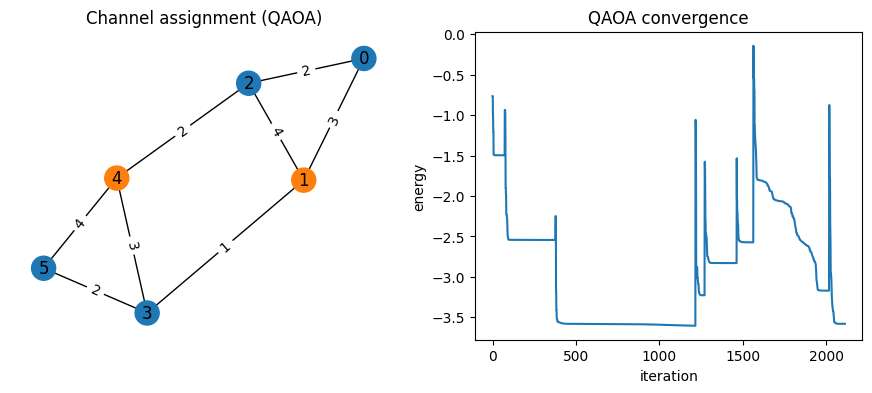

In [5]:
probs = Statevector(qc.assign_parameters(best.x)).probabilities_dict()
top = max(probs, key=probs.get)
bits = [int(c) for c in top[::-1]]  # Qiskit is little-endian
print("Most likely channels:", bits, "cut =", cut_value(bits),
      "prob =", round(probs[top],3))

fig, ax = plt.subplots(1,2, figsize=(11,4))
pos = nx.spring_layout(G, seed=3)
nx.draw(G, pos, ax=ax[0], with_labels=True,
        node_color=["tab:blue" if b==0 else "tab:orange" for b in bits])
nx.draw_networkx_edge_labels(G, pos, ax=ax[0],
        edge_labels=nx.get_edge_attributes(G,"weight"))
ax[0].set_title("Channel assignment (QAOA)")
ax[1].plot(history); ax[1].set_title("QAOA convergence")
ax[1].set_xlabel("iteration"); ax[1].set_ylabel("energy")
plt.show()